# LoFTR point tracking -- a test bench

LoFTR is a **detector-free** matcher: it chooses its own correspondence
locations (a coarse 1/8-resolution grid, refined to subpixel) and has no input
for "track these points". So handing it a starting contour takes two steps,
which is what `motion_estimator.methods.loftr` implements:

1. `LoFTRMatcher.match` -> semi-dense correspondences with confidences.
2. `displacement_at` -> a confidence-weighted, outlier-rejecting **local affine
   fit** of that correspondence field, evaluated at the points you named.

The affine part matters: a strain measurement *is* a displacement gradient, and
averaging displacements over a neighbourhood cannot represent one. See the
module docstrings for the reasoning and `tests/test_point_tracking.py` for the
closed-form checks (a 5% expansion must read as exactly +5% strain).

What this notebook answers:

- Does LoFTR find usable matches in echo speckle at all? (MegaDepth weights, so
  there is a real domain gap.)
- Does chaining frame-to-frame beat anchoring every frame to the reference?
- Do the resulting strain curves resemble MITT's on the same starting contour?

It runs on a **synthetic clip when the dataset drive is unmounted**, so the
plumbing is testable unplugged; every real-data cell says so when it falls back.

### First: torch before MKL

This cell must run before anything else in the kernel, and it is not
boilerplate. Skipping it gives

```
OSError: [WinError 127] The specified procedure could not be found.
Error loading "...\torch\lib\shm.dll" or one of its dependencies.
```

What actually triggers it, established by bisection rather than assumed: **a
BLAS call**, not an import. `import numpy`, `import scipy`, `import sklearn`,
`import h5py`, even `import matplotlib.pyplot` all leave torch loadable
afterwards. But `np.linalg.svd` -- or a matplotlib figure being *rendered* --
makes MKL load conda's `libiomp5md.dll`, and torch's `shm.dll` then resolves
against the wrong OpenMP runtime. So the hazard is not the order of the
imports, it is whether any array work has happened yet.

`MKL_THREADING_LAYER=TBB` removes the hazard outright, because MKL then threads
through TBB and never loads an OpenMP runtime for torch to collide with. Set
before the process starts, cell order stops mattering at all -- verified with a
BLAS call and a figure render ahead of the torch import. It is now in this
environment's kernelspec:

```
<conda env>/share/jupyter/kernels/python3/kernel.json
  "env": {"MKL_THREADING_LAYER": "TBB"}
```

so a kernel started after that change is already safe. This cell stays as the
fallback for any other environment, and `conftest.py` and
`dash_viewer/dash_main.py` carry the same two lines for non-notebook entry
points. See `docs/environment-notes.md`.

**The binding is per-process: once a kernel has raised this, no import order
repairs it. Restart the kernel.**

In [1]:
# Must run before any array work in this kernel. See the note above.
import os
import sys

os.environ.setdefault("MKL_THREADING_LAYER", "TBB")

try:
    import torch  # before MKL can claim libiomp5md.dll
except OSError as error:  # pragma: no cover - environment, not logic
    if "shm.dll" not in str(error) and "127" not in str(error):
        raise
    loaded = sorted(m for m in ("numpy", "scipy", "sklearn", "matplotlib")
                    if m in sys.modules)
    raise RuntimeError(
        "torch could not load its DLLs: MKL has already claimed the OpenMP "
        "runtime in this kernel"
        + (f" (already imported: {', '.join(loaded)})" if loaded else "")
        + ". Nothing in this process can undo that binding. "
        "FIX: restart the kernel, then run this cell first. "
        "PERMANENT FIX: MKL_THREADING_LAYER=TBB in the kernelspec env, which "
        "makes cell order irrelevant -- see the note above."
    ) from error

print("torch", torch.__version__, "| cuda", torch.cuda.is_available(),
      "| MKL_THREADING_LAYER", os.environ.get("MKL_THREADING_LAYER"))

torch 2.14.0+cu126 | cuda True | MKL_THREADING_LAYER TBB


## 0. Configuration

One cell to change. `SCALE = 1.0` matches at the native 500x500 -- ~0.26 s/pair
on an RTX 2060, so ~15 s for a 60-frame clip, doubled if you run both pairings.
`0.5` is ~4x cheaper, and on the synthetic clip it is already enough to cost
half the contour its support: cheap matching shows up as NaN tracks, not as a
quietly worse number.

In [2]:
import sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "motion_estimator").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

# --- what to load ----------------------------------------------------------
DATASET   = "Retest_dataset"   # Test_dataset is held out; see the split protocol
PATIENT   = None               # None -> the first complete clip in the cohort
VIEW      = "4ch"
MITT_VARIANT = "uni"           # the variant validate_strain.py reproduces exactly

# --- matcher ---------------------------------------------------------------
WEIGHTS        = "outdoor"     # MegaDepth. "indoor" (ScanNet) is the other option
SCALE          = 1.0           # 0.5 is ~4x cheaper and loses the finest speckle
MIN_CONFIDENCE = 0.2
USE_MASK       = True          # drop matches in the black corners outside the sector

# --- which weights ---------------------------------------------------------
# None = kornia's pretrained weights, which is what every number in this
# notebook was measured with. Point this at a run's best.pt to compare; the
# fine-tuned checkpoints all measured WORSE than pretrained (see
# SIMULATED_DATASET.md and TRACKING_EXPERIMENTS.md), so this is here to show
# that rather than to be switched on by default.
CHECKPOINT = None
# CHECKPOINT = "../artifacts/runs/2026-09-15_1537_spacing-floor/best.pt"

# --- interpolation ---------------------------------------------------------
INTERP = dict(radius=32.0, model="affine", min_neighbours=6, min_support=8,
              robust_passes=1, deviation_tolerance=3.0)

plt.rcParams.update({"figure.dpi": 110, "image.cmap": "gray"})
print("repo:", REPO)

repo: D:\PHD\Development\Python\Cardio_CAD


## 1. The clip

`data.mat` -> `prepare_clip` (the `loadIntervendorData.m` transform: crop to the
cardiac cycle, flip, permute to the clinical view) -> `(n_frames, rows, cols)`.

If the drive is unmounted this falls back to a synthetic clip built by warping
one speckle frame with a known radial contraction, which is useful in its own
right: the ground-truth displacement is then exactly known.

In [3]:
from motion_estimator.loaders.dataset_index import index_dataset
from motion_estimator.loaders.images.image_prep import frames_first, prepare_clip
from motion_estimator.loaders.annotations.scar_struct import read_view_analysis
from motion_estimator.loaders.images.srd_reader import read_clip


def synthetic_clip(n_frames=24, size=256, amplitude=0.06, seed=0):
    """A speckle frame warped by a known radial contraction and back.

    The deformation is a scaling about the image centre following a cardiac
    cycle, so the true strain curve is 100 * (factor - 1) exactly -- a
    controlled target for the whole chain.
    """
    from scipy import ndimage

    rng = np.random.default_rng(seed)
    base = ndimage.gaussian_filter(rng.random((size, size)).astype(np.float32), 1.5)
    base /= base.max()
    phase = np.sin(np.linspace(0, np.pi, n_frames))
    factors = 1.0 - amplitude * phase
    centre = (size - 1) / 2.0

    frames = []
    for factor in factors:
        # Pull-back sampling: output pixel p reads input centre + (p-centre)/factor
        grid = np.indices((size, size), dtype=float)
        source = centre + (grid - centre) / factor
        frames.append(ndimage.map_coordinates(base, source, order=1, mode="nearest"))
    return np.stack(frames), factors


ref = None
try:
    refs = [r for r in index_dataset(datasets=(DATASET,)) if r.is_complete]
    if PATIENT is not None:
        refs = [r for r in refs if r.key.patient == PATIENT]
    refs = [r for r in refs if r.key.view == VIEW]
    ref = refs[0] if refs else None
except (FileNotFoundError, OSError) as error:
    print("dataset root unavailable:", error)

if ref is not None:
    analysis = read_view_analysis(ref.scar_struct_path, ref.key.view)
    prepared = prepare_clip(read_clip(ref.clip_path),
                            cycle_frame_limits=analysis.cycle_frame_limits)
    frames = frames_first(prepared.images).astype(np.float32)
    # pixel_spacing_mm is voxelsize[[1, 0, 2]], i.e. (row, col) = (y, x).
    # Two names, because the two orders are needed and confusing them silently
    # rescales strain -- row and column spacing differ across this cohort
    # (~0.26-0.37 mm), so it is not a rounding-level mistake.
    spacing_rc = np.asarray(prepared.pixel_spacing_mm, dtype=float).ravel()[:2]
    spacing_xy = spacing_rc[::-1]
    true_factors = None
    print("clip:", ref.key, "| frames", frames.shape,
          "| mm/px (row, col)", spacing_rc.round(4))
else:
    frames, true_factors = synthetic_clip()
    spacing_rc = np.array([0.3, 0.3])
    spacing_xy = spacing_rc[::-1]
    analysis = None
    print("SYNTHETIC clip:", frames.shape, "-- real-data cells will say so")

clip: Retest_dataset/IV02/4ch | frames (44, 500, 500) | mm/px (row, col) [0.2605 0.3172]


## 2. The points to track

This is the input the question was about. Priority order:

1. **MITT's contour at its reference frame** -- the best choice for a first
   test, because MITT also stores where those same points ended up on every
   later frame, so LoFTR's tracks have something to be compared against
   point-by-point rather than only in aggregate.
2. `scar_struct`'s stored contour -- available for every clip, but its
   coordinate convention is unverified (see the package README), so check it
   visually before trusting a number derived from it.
3. A synthetic arc, for the fallback clip.

MITT stores points in **millimetres**; `loadIntervendorData.m:20-21` converts
with `pixel = mm / spacing + 1`, and the +1 is the 1-based origin this package
keeps throughout.

MITT: IV02_4ch.mat | points (44, 72) | esFrame 20 | refFrame 1
72 starting points from MITT uni, on frame 0


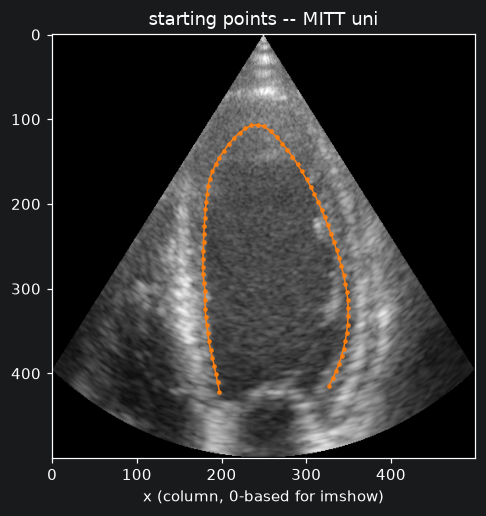

In [4]:
from motion_estimator.loaders.annotations.mitt import mitt_path, read_mitt

mitt = None
if ref is not None:
    path = mitt_path(ref.key.patient, ref.key.view, ref.key.dataset, MITT_VARIANT)
    if path.is_file():
        mitt = read_mitt(path)
        print("MITT:", path.name, "| points", mitt.points_x.shape,
              "| esFrame", mitt.es_frame, "| refFrame", mitt.ref_frame)
    else:
        print("no MITT result at", path)

# to_clinical_view is out[i, j] == tissue[n_rows - 1 - j, i]: clinical ROWS come
# from raw COLUMNS. So MITT's stored axes are transposed relative to the image,
# and pixel_spacing_mm (voxelsize[[1, 0, 2]]) is ordered (row, col) to match --
# spacing[0] scales y, spacing[1] scales x. Getting either wrong rotates the
# contour 90 degrees off the myocardium.
FLIP_X = False   # set from what the plot below shows; the flip half of the
FLIP_Y = False   # permute is not pinned down by anything we can read here

if mitt is not None:
    # mm -> 1-based pixels, the convention tracking/ and strain/ share.
    mitt_x = mitt.points_y / spacing_rc[1] + 1.0
    mitt_y = mitt.points_x / spacing_rc[0] + 1.0
    if FLIP_X:
        mitt_x = frames.shape[2] + 1.0 - mitt_x
    if FLIP_Y:
        mitt_y = frames.shape[1] + 1.0 - mitt_y
    reference_frame = mitt.ref_frame - 1          # stored 1-based
    start_x, start_y = mitt_x[reference_frame], mitt_y[reference_frame]
    es_frame = mitt.es_frame
    segments = mitt.segments
    source = f"MITT {MITT_VARIANT}"
elif analysis is not None:
    endo = np.asarray(analysis.surf_endo, dtype=float)
    start_x, start_y = endo[:, 0], endo[:, 1]     # convention UNVERIFIED
    reference_frame, es_frame, segments = 0, len(frames) // 3, None
    source = "scar_struct surf_endo (convention unverified)"
else:
    angle = np.linspace(0.25 * np.pi, 0.75 * np.pi, 60)
    centre, radius = (frames.shape[1] - 1) / 2.0, 70.0
    start_x = centre + 1.0 + radius * np.cos(angle)
    start_y = centre + 1.0 + radius * np.sin(angle)
    reference_frame, es_frame, segments = 0, len(frames) // 2, None
    source = "synthetic arc"

start_x = np.asarray(start_x, dtype=float).ravel()
start_y = np.asarray(start_y, dtype=float).ravel()
print(f"{start_x.size} starting points from {source}, on frame {reference_frame}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(frames[reference_frame])
ax.plot(start_x - 1, start_y - 1, ".-", color="tab:orange", ms=4, lw=1)
ax.set_title(f"starting points -- {source}")
ax.set_xlabel("x (column, 0-based for imshow)")
plt.show()

## 3. The sector mask

The 500x500 frames are zero outside the ultrasound sector. Two constant-zero
regions match each other confidently with an arbitrary displacement, so those
matches are dropped rather than down-weighted. The mask is derived from the clip
itself -- a pixel that is non-zero in any frame is inside the sector -- which
avoids depending on `<view>/track/IV##_<view>_mask.raw` being present.

sector covers 53.5% of the frame


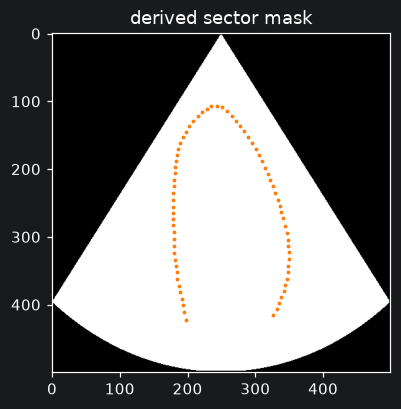

In [5]:
from scipy import ndimage

sector = frames.max(axis=0) > (np.nanmax(frames) * 0.01)
sector = ndimage.binary_closing(sector, np.ones((5, 5)))
sector = ndimage.binary_fill_holes(sector)
mask = sector if USE_MASK else None
print(f"sector covers {100 * sector.mean():.1f}% of the frame")

inside = sector[np.rint(start_y - 1).astype(int).clip(0, sector.shape[0] - 1),
                np.rint(start_x - 1).astype(int).clip(0, sector.shape[1] - 1)]
if not inside.all():
    print(f"WARNING: {(~inside).sum()} starting points fall outside the mask -- "
          "they will have no support and track as NaN")

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(sector)
ax.plot(start_x - 1, start_y - 1, ".", color="tab:orange", ms=3)
ax.set_title("derived sector mask")
plt.show()

## 4. One pair, looked at closely

Before running a whole clip: does LoFTR find anything in echo speckle, where do
the matches sit, and how confident are they? The first thing to check is that
the matches are *inside the myocardium* -- a matcher that only fires on the
sector borders and the ECG overlay will produce a smooth-looking but meaningless
track.

In [6]:
from motion_estimator.methods.loftr import LoFTRMatcher

matcher = LoFTRMatcher(weights=WEIGHTS, min_confidence=MIN_CONFIDENCE,
                       mask=mask, scale=SCALE)
print("device:", matcher.device, "| weights:", WEIGHTS, "| scale:", SCALE)

pair = (reference_frame, min(reference_frame + 1, len(frames) - 1))
start = time.perf_counter()
one = matcher.match(frames[pair[0]], frames[pair[1]])
elapsed = time.perf_counter() - start
print(f"{one.n_matches} matches in {elapsed:.2f}s | "
      f"confidence {one.confidence.min():.2f}-{one.confidence.max():.2f} | "
      f"|displacement| median {np.median(np.hypot(*one.displacement.T)):.2f} px")

C:\Users\andre\Anaconda3\envs\cardioCad\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


device: cuda | weights: outdoor | scale: 1.0
1217 matches in 1.17s | confidence 0.20-1.00 | |displacement| median 1.47 px


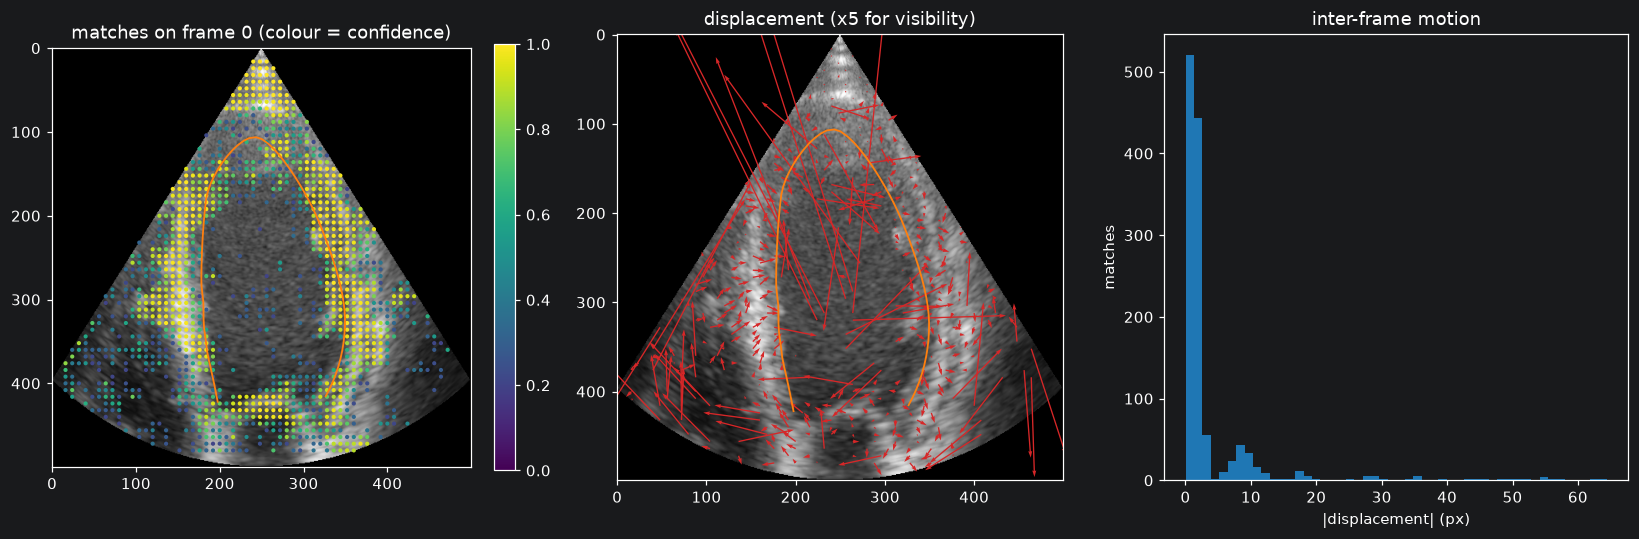

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(frames[pair[0]])
scatter = axes[0].scatter(one.xy0[:, 0], one.xy0[:, 1], c=one.confidence,
                          s=3, cmap="viridis", vmin=0, vmax=1)
axes[0].plot(start_x - 1, start_y - 1, "-", color="tab:orange", lw=1.2)
axes[0].set_title(f"matches on frame {pair[0]} (colour = confidence)")
fig.colorbar(scatter, ax=axes[0], fraction=0.046)

step = max(one.n_matches // 400, 1)
axes[1].imshow(frames[pair[0]])
axes[1].quiver(one.xy0[::step, 0], one.xy0[::step, 1],
               one.displacement[::step, 0], one.displacement[::step, 1],
               color="tab:red", angles="xy", scale_units="xy", scale=0.15, width=0.003)
axes[1].plot(start_x - 1, start_y - 1, "-", color="tab:orange", lw=1.2)
axes[1].set_title("displacement (x5 for visibility)")

axes[2].hist(np.hypot(*one.displacement.T), bins=50, color="tab:blue")
axes[2].set_xlabel("|displacement| (px)")
axes[2].set_ylabel("matches")
axes[2].set_title("inter-frame motion")
plt.tight_layout()
plt.show()

### The interpolated field at the contour points

`displacement_at` reduces those matches to one displacement per contour point.
`support` is the diagnostic to read first: it counts the matches that survived
distance weighting *and* outlier rejection for each point. A zero means the
matcher found nothing within `radius` -- a different, and more honest, failure
than a confidently wrong displacement.

support: min 20, median 35, max 49 | 0 of 72 points unsupported


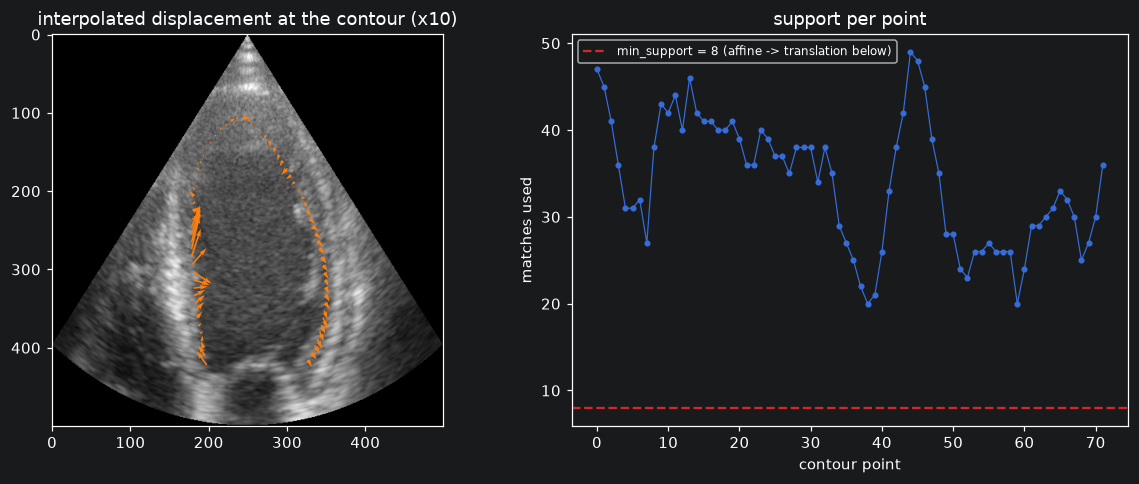

In [8]:
from motion_estimator.methods.loftr import displacement_at

dx, dy, support = displacement_at(one, start_x, start_y, **INTERP)
print(f"support: min {support.min()}, median {int(np.median(support))}, "
      f"max {support.max()} | {np.isnan(dx).sum()} of {dx.size} points unsupported")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(frames[pair[0]])
axes[0].quiver(start_x - 1, start_y - 1, dx, dy, color="tab:orange",
               angles="xy", scale_units="xy", scale=0.1, width=0.004)
axes[0].set_title("interpolated displacement at the contour (x10)")

axes[1].plot(support, ".-", lw=0.8)
axes[1].axhline(INTERP["min_support"], color="tab:red", ls="--",
                label=f"min_support = {INTERP['min_support']} (affine -> translation below)")
axes[1].set_xlabel("contour point")
axes[1].set_ylabel("matches used")
axes[1].legend(fontsize=8)
axes[1].set_title("support per point")
plt.tight_layout()
plt.show()

## 5. Track the clip, both ways

`consecutive` chains frame-to-frame (small baseline, drift compounds).
`reference` matches frame 0 to frame *k* every time (no drift, wide baseline at
end-systole -- LoFTR's home turf, but where speckle decorrelation is worst).

The matches are kept so section 7 can re-interpolate them under different
settings without touching the GPU again.

In [9]:
from motion_estimator.methods.loftr import track_points

matches, tracks = {}, {}
for pairing in ("consecutive", "reference"):
    start = time.perf_counter()
    matches[pairing] = matcher.match_sequence(
        frames, reference=None if pairing == "consecutive" else reference_frame,
        progress=True)
    tracks[pairing] = track_points(
        frames, start_x, start_y, matches=matches[pairing], pairing=pairing,
        reference_frame=0 if pairing == "consecutive" else reference_frame,
        **INTERP)
    result = tracks[pairing]
    lost = (result.lost >= 0).sum()
    print(f"{pairing:12s} {time.perf_counter() - start:6.1f}s | "
          f"matches/pair {int(np.median(result.n_matches)):5d} | "
          f"{lost} of {result.n_points} points lost | "
          f"support median {int(np.median(result.support[result.support > 0]))}")

C:\Users\andre\Anaconda3\envs\cardioCad\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
LoFTR: 100%|██████████| 43/43 [00:09<00:00,  4.35pair/s]


consecutive    13.6s | matches/pair  1217 | 0 of 72 points lost | support median 38


LoFTR: 100%|██████████| 44/44 [00:10<00:00,  4.10pair/s]


reference      13.7s | matches/pair   505 | 52 of 72 points lost | support median 15


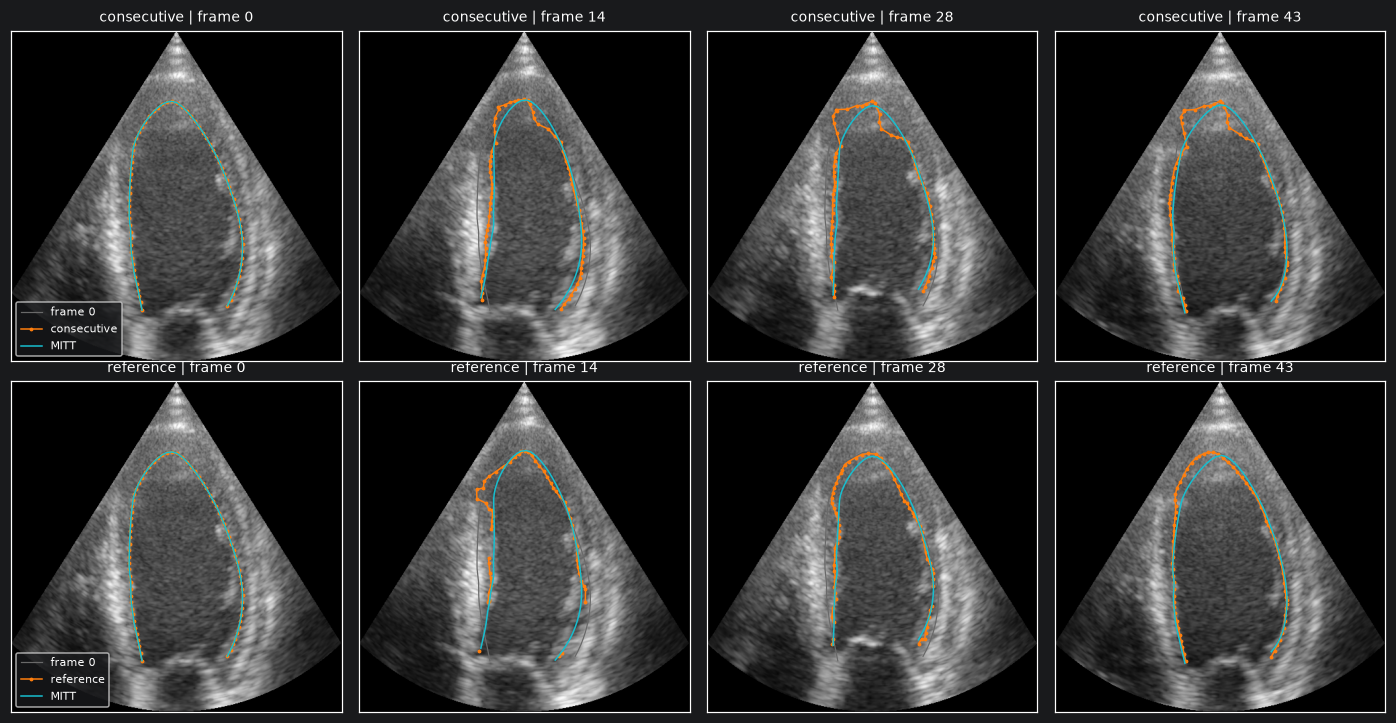

In [10]:
phases = np.linspace(0, len(frames) - 1, 4).astype(int)
fig, axes = plt.subplots(2, len(phases), figsize=(3.2 * len(phases), 6.6))
for row, pairing in enumerate(("consecutive", "reference")):
    result = tracks[pairing]
    for col, frame in enumerate(phases):
        ax = axes[row, col]
        ax.imshow(frames[frame])
        ax.plot(start_x - 1, start_y - 1, "-", color="dimgray", lw=0.8,
                label="frame 0" if col == 0 else None)
        ax.plot(result.x[frame] - 1, result.y[frame] - 1, ".-", color="tab:orange",
                ms=3, lw=1, label=pairing if col == 0 else None)
        if mitt is not None:
            ax.plot(mitt_x[frame] - 1, mitt_y[frame] - 1, "-", color="tab:cyan",
                    lw=1, label="MITT" if col == 0 else None)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{pairing} | frame {frame}", fontsize=9)
        if col == 0:
            ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

### Against MITT, point by point

MITT tracked the *same* points, so the two can be differenced directly. This is
not a ground truth -- MITT is a speckle tracker with its own error -- but a
disagreement of tens of pixels means one of them is wrong, and the drift plot
says which failure mode it is: a slope is accumulation, a jump is a lost frame.

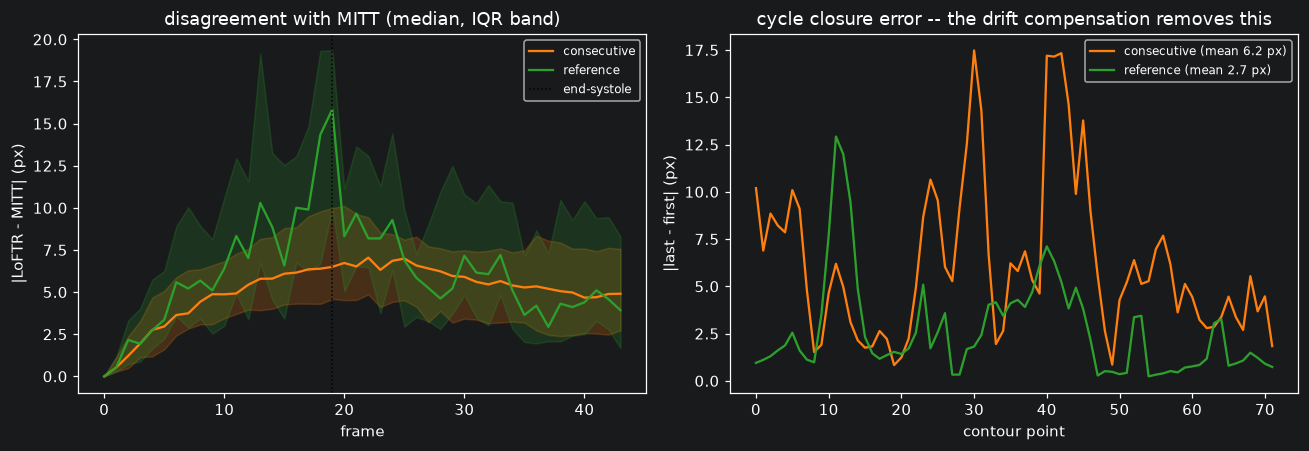

In [11]:
if mitt is None:
    print("no MITT result for this clip -- skipped")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for pairing, colour in (("consecutive", "tab:orange"), ("reference", "tab:green")):
        result = tracks[pairing]
        error = np.hypot(result.x - mitt_x, result.y - mitt_y)
        axes[0].plot(np.nanmedian(error, axis=1), color=colour, label=pairing)
        axes[0].fill_between(np.arange(len(frames)),
                             np.nanpercentile(error, 25, axis=1),
                             np.nanpercentile(error, 75, axis=1),
                             color=colour, alpha=0.2)
        closure = np.hypot(result.x[-1] - result.x[0], result.y[-1] - result.y[0])
        axes[1].plot(closure, color=colour, label=f"{pairing} (mean {np.nanmean(closure):.1f} px)")
    axes[0].axvline(es_frame - 1, color="k", ls=":", lw=1, label="end-systole")
    axes[0].set_xlabel("frame"); axes[0].set_ylabel("|LoFTR - MITT| (px)")
    axes[0].set_title("disagreement with MITT (median, IQR band)")
    axes[0].legend(fontsize=8)
    axes[1].set_xlabel("contour point"); axes[1].set_ylabel("|last - first| (px)")
    axes[1].set_title("cycle closure error -- the drift compensation removes this")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. Strain

The tracks go through the same `strain/` code the MITT curves were validated
against (`validate_strain.py`: 236/236 reproduced, worst residual 1.4e-13), so
any difference here is the tracker's, not the arithmetic's.

Two settings that change the answer by percentage points and must not be
guessed -- both pinned empirically in the package README:

- `open_contour=True`. The LV longitudinal contour runs base-apex-base and is
  not closed; closing it adds a spurious base-to-base chord.
- `drift_comp`. MITT's stored curves were produced with it **off**, so the
  comparison below uses MITT's own recorded flag. For `pairing="reference"`
  there is no accumulated drift to compensate, which is the interesting part.

In [12]:
from motion_estimator.strain.curve import compute_strain

drift_comp = bool(mitt.drift_compensated) if mitt is not None else False
results = {}
for pairing in ("consecutive", "reference"):
    x_mm, y_mm = tracks[pairing].to_mm(spacing_xy)
    results[pairing] = compute_strain(x_mm, y_mm, es_frame=es_frame,
                                      drift_comp=drift_comp, open_contour=True)

rows = [(name, r.value_es, r.value_peak_systolic) for name, r in results.items()]
if mitt is not None and mitt.strain_curve is not None:
    reference_result = compute_strain(mitt.points_x, mitt.points_y, mitt.es_frame,
                                      drift_comp=drift_comp, open_contour=True)
    rows.append(("MITT", reference_result.value_es, reference_result.value_peak_systolic))

print(f"{'source':14s} {'GLS at ES':>10s} {'peak systolic':>14s}")
for name, value_es, peak in rows:
    print(f"{name:14s} {value_es:10.2f} {peak:14.2f}")

if ref is not None:
    from motion_estimator.loaders.annotations.gt_strain import read_gt_strain

    target = read_gt_strain(ref.gt_strain_path).target_vector(ref.key.view)
    print(f"\nGE vendor ground truth GLS: {float(np.asarray(target).ravel()[-1]):.2f}")
    print("(GE's own tracking, not a tracking-independent truth -- and its "
          "segmental values come from a different contour than ours)")

source          GLS at ES  peak systolic
consecutive          0.34          -0.17
reference             nan          -0.17
MITT                -4.24          -4.24

GE vendor ground truth GLS: -8.80
(GE's own tracking, not a tracking-independent truth -- and its segmental values come from a different contour than ours)


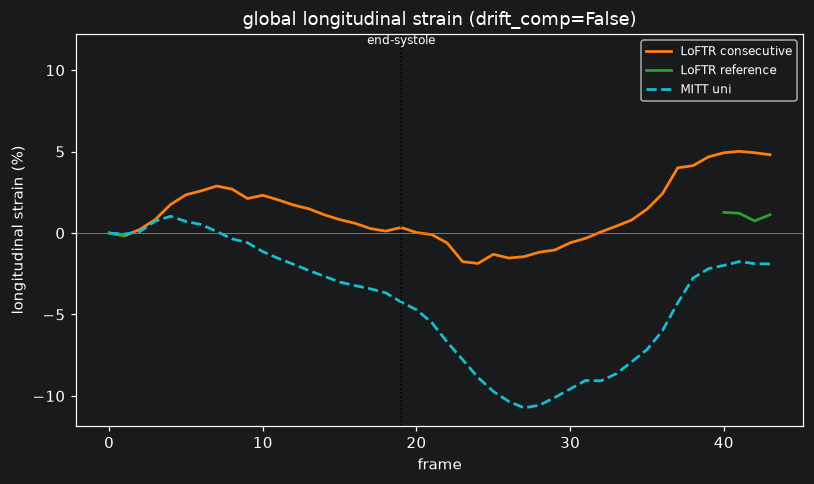

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for pairing, colour in (("consecutive", "tab:orange"), ("reference", "tab:green")):
    ax.plot(results[pairing].curve.numpy(), color=colour, lw=1.8, label=f"LoFTR {pairing}")
if mitt is not None and mitt.strain_curve is not None:
    ax.plot(np.asarray(mitt.strain_curve).ravel(), color="tab:cyan", lw=1.8,
            ls="--", label=f"MITT {MITT_VARIANT}")
if true_factors is not None:
    ax.plot(100.0 * (true_factors - 1.0), color="k", lw=1.5, ls=":",
            label="synthetic truth")
ax.axvline(es_frame - 1, color="k", ls=":", lw=1)
ax.annotate("end-systole", (es_frame - 1, ax.get_ylim()[1]), fontsize=8,
            ha="center", va="top")
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("frame"); ax.set_ylabel("longitudinal strain (%)")
ax.set_title(f"global longitudinal strain (drift_comp={drift_comp})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Segmental

Six segments, from MITT's own point-to-segment map. `compute_strain` takes a
subset of the contour columns, so a segment is just a slice of the same call.

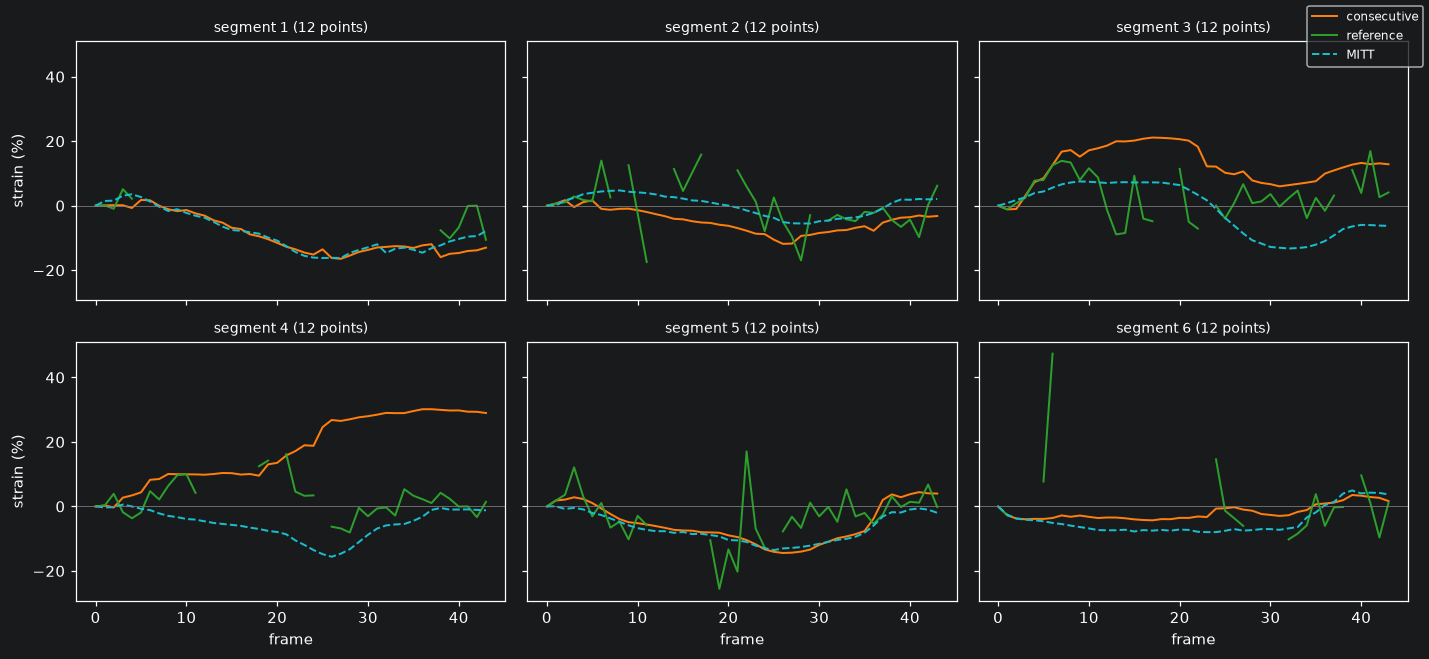

In [14]:
if segments is None or not segments.size:
    print("no segment map for this clip -- skipped")
else:
    n_segments = int(segments.max()) + 1
    fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
    for segment, ax in zip(range(n_segments), axes.ravel()):
        columns = np.flatnonzero(segments == segment)
        for pairing, colour in (("consecutive", "tab:orange"), ("reference", "tab:green")):
            x_mm, y_mm = tracks[pairing].to_mm(spacing_xy)
            curve = compute_strain(x_mm[:, columns], y_mm[:, columns], es_frame,
                                   drift_comp=drift_comp, open_contour=True)
            ax.plot(curve.curve.numpy(), color=colour, lw=1.3)
        if mitt is not None and segment < len(mitt.segmental_curves):
            ax.plot(np.asarray(mitt.segmental_curves[segment]).ravel(),
                    color="tab:cyan", ls="--", lw=1.3)
        ax.axhline(0, color="gray", lw=0.5)
        ax.set_title(f"segment {segment + 1} ({columns.size} points)", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("frame")
    for ax in axes[:, 0]:
        ax.set_ylabel("strain (%)")
    fig.legend(["consecutive", "reference", "MITT"], loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()

## 7. Sweeping the interpolation, for free

The correspondences are already computed, so `track_points(matches=...)` re-runs
only the interpolation. This is where the two design choices get measured rather
than argued: `radius` (how local "local affine" is) and `model` (affine vs a
weighted mean).

Expect the translation model to read *lower* strain -- it cannot represent a
displacement gradient, and a strain measurement is one. If it does not, the
matches near the contour are too sparse for the affine fit to be doing anything,
which `support` will confirm.

In [15]:
sweep = []
for pairing in ("consecutive", "reference"):
    for model in ("affine", "translation"):
        for radius in (16.0, 24.0, 32.0, 48.0):
            settings = {**INTERP, "model": model, "radius": radius}
            result = track_points(None, start_x, start_y, matches=matches[pairing],
                                  pairing=pairing,
                                  reference_frame=0 if pairing == "consecutive" else reference_frame,
                                  **settings)
            x_mm, y_mm = result.to_mm(spacing_xy)
            strain = compute_strain(x_mm, y_mm, es_frame, drift_comp=drift_comp,
                                    open_contour=True)
            error = (np.nanmedian(np.hypot(result.x - mitt_x, result.y - mitt_y))
                     if mitt is not None else np.nan)
            sweep.append(dict(pairing=pairing, model=model, radius=radius,
                              gls=strain.value_es, lost=int((result.lost >= 0).sum()),
                              support=int(np.median(result.support[result.support > 0]))
                              if (result.support > 0).any() else 0,
                              vs_mitt_px=error))

try:
    import pandas as pd

    table = pd.DataFrame(sweep)
    display(table.round(2))
except ImportError:
    for row in sweep:
        print(row)

,pairing,model,radius,gls,lost,support,vs_mitt_px
0,consecutive,affine,16.0,NaN,47,11,3.61
1,consecutive,affine,24.0,NaN,8,23,5.25
2,consecutive,affine,32.0,0.34,0,38,5.03
3,consecutive,affine,48.0,-2.58,0,77,5.41
4,consecutive,translation,16.0,NaN,45,11,3.76
5,consecutive,translation,24.0,NaN,7,23,4.78
6,consecutive,translation,32.0,-1.36,0,38,4.39
7,consecutive,translation,48.0,-3.50,0,76,4.25
8,reference,affine,16.0,NaN,72,7,3.65
9,reference,affine,24.0,NaN,70,10,5.10


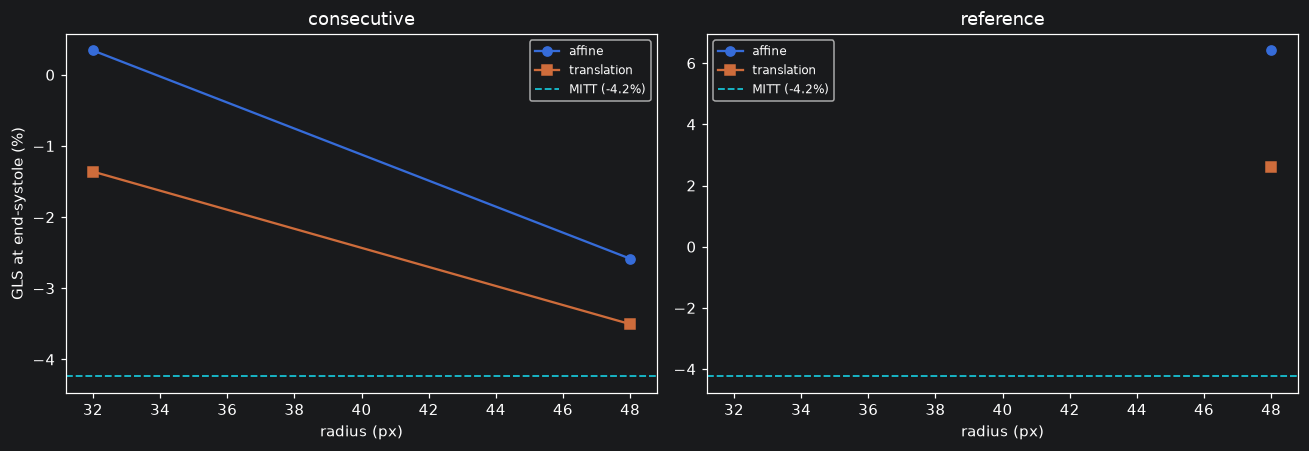

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, pairing in zip(axes, ("consecutive", "reference")):
    for model, marker in (("affine", "o"), ("translation", "s")):
        subset = [r for r in sweep if r["pairing"] == pairing and r["model"] == model]
        ax.plot([r["radius"] for r in subset], [r["gls"] for r in subset],
                marker=marker, label=model)
    if mitt is not None and mitt.strain_curve is not None:
        ax.axhline(reference_result.value_es, color="tab:cyan", ls="--", lw=1.2,
                   label=f"MITT ({reference_result.value_es:.1f}%)")
    ax.set_xlabel("radius (px)"); ax.set_title(pairing)
    ax.legend(fontsize=8)
axes[0].set_ylabel("GLS at end-systole (%)")
plt.tight_layout()
plt.show()

### A property worth knowing before reading any of this

Arc length is a **sum of local distances**, and the contour is sampled about
1.9 px apart. So a single point given a wrong displacement does not perturb the
strain curve, it destroys that frame: while this notebook was being built, one
contour point with three supporting matches was handed a 40 px displacement on
a clip whose true motion was 4 px, and that frame read **+21% strain** instead
of -6%.

Smoothing the tracks along the contour does not fix it -- the error is not
jitter, it is one confidently wrong point. Three guards in `displacement_at`
address it, and they are why the defaults look conservative:

| guard | default | what it catches |
|---|---|---|
| `min_neighbours` | 6 | too little support to fit *or* to check a fit against -> NaN |
| conditioning | fixed | collinear support cannot fix a gradient -> weighted mean |
| `deviation_tolerance` | 3.0 | the fit predicting far outside its support -> weighted mean |

So **read the NaN count before reading the curve**. A frame with any NaN point
has no arc length, and `strain_from_arc_length` propagates that as NaN rather
than filling it in -- a gap in the curve is the tracker reporting failure, not
a plotting artefact. `TrackResult.lost` says which points, and `support` says
whether the cause was missing matches or rejected ones.

## 8. What to read off this

Checks worth running before drawing any conclusion:

- **Are the matches in the myocardium?** Section 4's confidence map. If LoFTR is
  only firing on the sector edges and text overlays, nothing downstream means
  anything, and the answer is fine-tuning or a different matcher, not a wider
  `radius`.
- **Is `support` healthy along the whole contour?** The basal points sit near the
  sector edge and lose support first; a segmental curve built on `support = 0`
  columns is NaN, not zero.
- **Does the translation model read lower strain than affine?** If yes, the local
  affine fit is doing real work. If the two agree, the matches near the contour
  are too sparse to constrain a gradient.
- **`consecutive` vs `reference`.** Compare `cycle closure error` in section 5
  with `vs_mitt_px` in section 7. Anchoring to the reference frame trades drift
  for wide-baseline matching; which wins is a per-cohort empirical question, and
  it decides whether drift compensation is needed at all.

Not settled by this notebook:

- **The domain gap.** These are MegaDepth weights on ultrasound speckle. Try
  `WEIGHTS = "indoor"` and `SCALE = 1.0` before concluding anything about LoFTR
  as a method; the pretrained model is a floor, not a ceiling.
- **Whether GE's GLS is the right target.** It is GE's own tracking on GE's own
  contour, so agreeing with it is not the same as being correct.
- **Speed.** ~0.26 s/pair at 500x500 means a cohort pass over 236 clips is about
  an hour per pairing. Cache `Matches`, as section 7 relies on, before scaling up.

## 9. Why coverage fails -- match density

Everything below is the argument that the interpolation is starved of matches,
made visible rather than asserted. The claim under test:

> LoFTR returns a few hundred matches over a 500x500 frame. At ~14 px mean
> spacing, a radius-16 neighbourhood holds about 4 of them -- fewer than
> `min_neighbours=6` -- so `displacement_at` returns NaN across most of the
> image, not specifically at the endocardial border.

If that is right, then offsetting the contour into the myocardium cannot help
(measured: coverage 32.1% -> 34.0% for a 5.2 mm offset), and neither can
contrast preprocessing (measured: CLAHE 32.1% -> 37.1%, at the cost of
accuracy). The lever would have to be the radius, the neighbour floor, or a
denser method.

In [17]:
from scipy.spatial import cKDTree

pair_for_density = (reference_frame, min(reference_frame + 6, len(frames) - 1))
dense = matcher.match(frames[pair_for_density[0]], frames[pair_for_density[1]])

sector_px = int(sector.sum())
spacing = np.sqrt(sector_px / max(dense.n_matches, 1))
tree = cKDTree(dense.xy0)
nearest, _ = tree.query(dense.xy0, k=2)

print(f"frame pair {pair_for_density}  (gap {pair_for_density[1] - pair_for_density[0]})")
print(f"  matches                {dense.n_matches}")
print(f"  sector area            {sector_px} px")
print(f"  area per match         {sector_px / max(dense.n_matches, 1):.0f} px^2"
      f"  -> mean spacing ~{spacing:.1f} px")
print(f"  nearest-neighbour gap  median {np.median(nearest[:, 1]):.1f} px")

for radius in (16.0, 24.0, 32.0, 48.0):
    expected = dense.n_matches * np.pi * radius ** 2 / sector_px
    print(f"  radius {radius:4.0f}: expect ~{expected:5.1f} matches per disc"
          f"   {'BELOW' if expected < INTERP['min_neighbours'] else 'above'}"
          f" min_neighbours={INTERP['min_neighbours']}")

frame pair (0, 6)  (gap 6)
  matches                596
  sector area            133788 px
  area per match         224 px^2  -> mean spacing ~15.0 px
  nearest-neighbour gap  median 8.0 px
  radius   16: expect ~  3.6 matches per disc   BELOW min_neighbours=6
  radius   24: expect ~  8.1 matches per disc   above min_neighbours=6
  radius   32: expect ~ 14.3 matches per disc   above min_neighbours=6
  radius   48: expect ~ 32.2 matches per disc   above min_neighbours=6


### The support map

For every pixel, how many matches lie within `radius`. Anything below
`min_neighbours` returns NaN, so the red region is where tracking cannot work
no matter where the contour is put. Overlaying the contour shows whether the
border is special or merely inside a much larger dead zone.

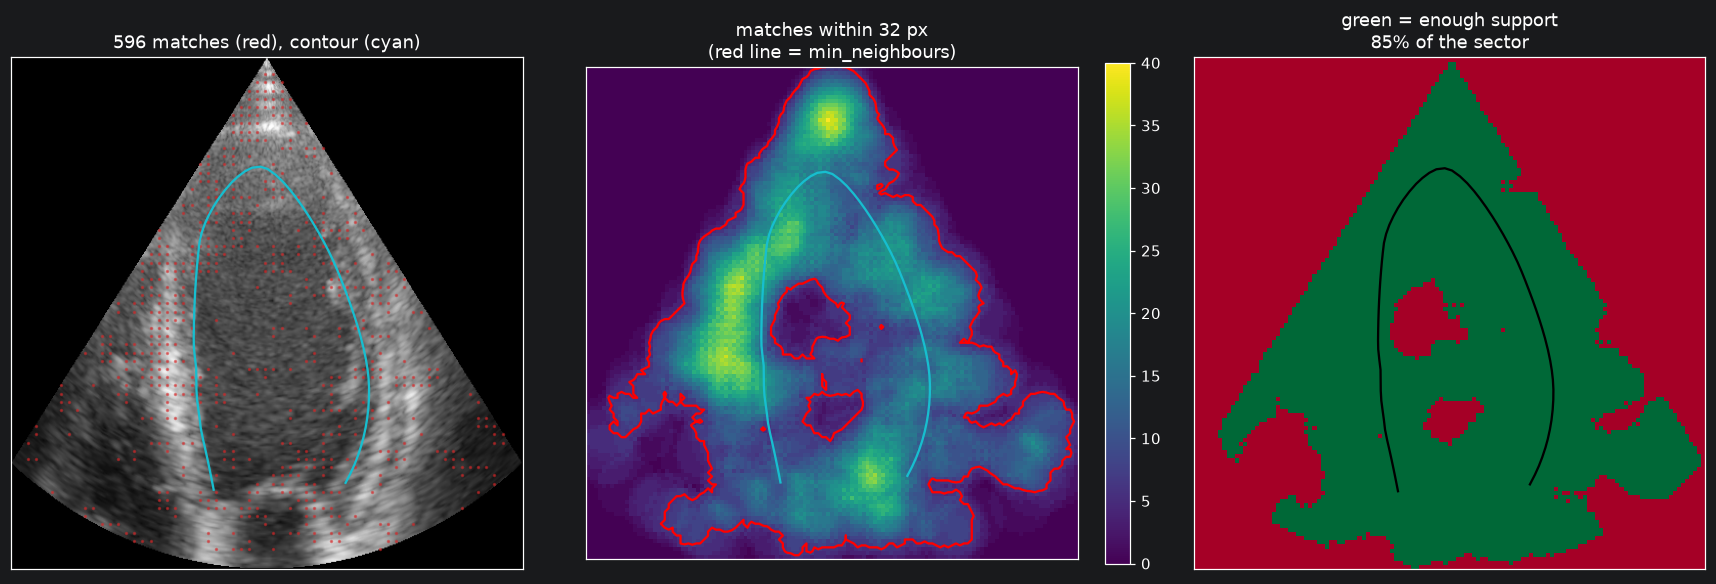

In [18]:
radius_map = INTERP["radius"]
step = 4  # the map is only for looking at, so a coarse grid is plenty
rows_grid = np.arange(0, frames.shape[1], step)
cols_grid = np.arange(0, frames.shape[2], step)
grid_x, grid_y = np.meshgrid(cols_grid, rows_grid)
counts = np.array(
    tree.query_ball_point(np.c_[grid_x.ravel(), grid_y.ravel()], radius_map,
                          return_length=True)
).reshape(grid_x.shape)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
axes[0].imshow(frames[pair_for_density[0]])
axes[0].scatter(dense.xy0[:, 0], dense.xy0[:, 1], s=1.5, c="tab:red", alpha=0.5)
axes[0].plot(start_x - 1, start_y - 1, "-", color="tab:cyan", lw=1.5)
axes[0].set_title(f"{dense.n_matches} matches (red), contour (cyan)")

image = axes[1].imshow(counts, extent=[0, frames.shape[2], frames.shape[1], 0],
                       cmap="viridis")
axes[1].contour(grid_x, grid_y, counts, levels=[INTERP["min_neighbours"]],
                colors="red", linewidths=1.5)
axes[1].plot(start_x - 1, start_y - 1, "-", color="tab:cyan", lw=1.5)
axes[1].set_title(f"matches within {radius_map:.0f} px\n(red line = min_neighbours)")
fig.colorbar(image, ax=axes[1], fraction=0.046)

usable = counts >= INTERP["min_neighbours"]
axes[2].imshow(usable & sector[::step, ::step], cmap="RdYlGn")
axes[2].plot((start_x - 1) / step, (start_y - 1) / step, "-", color="black", lw=1.5)
axes[2].set_title(f"green = enough support\n{100 * (usable & sector[::step, ::step]).sum() / max(sector[::step, ::step].sum(), 1):.0f}% of the sector")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### Coverage against radius and the neighbour floor

The two knobs that trade coverage for accuracy. Read this with the gain table
in section 10: a wider radius recovers points but averages the displacement
over a larger neighbourhood, which shrinks the very gradient strain measures.

In [19]:
from motion_estimator.methods.loftr import displacement_at

print(f"{'radius':>7s} " + "".join(f"{'min_nb=' + str(k):>12s}" for k in (3, 4, 6, 8)))
for radius in (16.0, 24.0, 32.0, 48.0):
    cells = []
    for floor in (3, 4, 6, 8):
        dx, dy, _ = displacement_at(
            dense, start_x, start_y, radius=radius, min_neighbours=floor,
            model=INTERP["model"],
        )
        cells.append(f"{100 * np.isfinite(dx).mean():11.0f}%")
    print(f"{radius:7.0f} " + "".join(cells))
print("\npercentage of contour points that get a displacement at all")

 radius     min_nb=3    min_nb=4    min_nb=6    min_nb=8
     16          68%         51%         29%         15%
     24         100%         96%         81%         64%
     32         100%        100%        100%         97%
     48         100%        100%        100%        100%

percentage of contour points that get a displacement at all


## 10. The gain measurement, in one cell

The finding that explained the flat strain curves. `diagnose_gain` measured
this against exact ground truth on the simulated cohort; the point of repeating
it here is that it is visible on your own clip without any ground truth, as the
ratio of the displacement LoFTR reports to the displacement implied by a
larger frame gap.

Measured on simulated data, where the truth is known:

| frame gap | true motion | raw LoFTR gain | interp r=16 | interp r=32 |
|---|---|---|---|---|
| 1 | ~1 px | 0.798 | 0.754 | 0.743 |
| 2 | ~2 px | 0.859 | 0.843 | 0.831 |
| 6 | ~6 px | 0.979 | 0.977 | 0.958 |
| 12 | ~12 px | 0.987 | 0.984 | 0.968 |

LoFTR's fine level regresses its subpixel offset as the spatial expectation of
a softmax heatmap, which is biased toward the window centre and shrinks small
offsets toward zero. These clips move ~1 px per frame, so consecutive chaining
runs at a gain near 0.8 and strain reads ~20% low. That is why
`pairing="consecutive"` is the wrong default here, and why no amount of
fine-tuning or drift correction addressed the symptom.

In [20]:
# NOT a valid test of shrinkage, kept only to show why: it assumes the true
# displacement doubles when the frame gap doubles, and cardiac motion does not --
# it accelerates through systole and reverses in diastole. The observed ratios
# (1.54, 3.45, 1.93 on IV02) reflect that non-linearity, not the matcher. The
# clean measurement needs known ground truth, which only the simulated cohort
# has: see scripts/diagnose_gain.py and the table above.
base = reference_frame
for gap in (1, 2, 4):
    if base + 2 * gap >= len(frames):
        continue
    short = matcher.match(frames[base], frames[base + gap])
    long = matcher.match(frames[base], frames[base + 2 * gap])
    short_median = np.median(np.hypot(*short.displacement.T))
    long_median = np.median(np.hypot(*long.displacement.T))
    print(f"gap {gap:2d} -> {short_median:5.2f} px | gap {2 * gap:2d} -> "
          f"{long_median:5.2f} px | ratio {long_median / max(short_median, 1e-9):4.2f}"
          f"   (2.00 would mean no shrinkage)")

gap  1 ->  1.47 px | gap  2 ->  2.26 px | ratio 1.54   (2.00 would mean no shrinkage)
gap  2 ->  2.26 px | gap  4 ->  7.79 px | ratio 3.45   (2.00 would mean no shrinkage)
gap  4 ->  7.79 px | gap  8 -> 15.04 px | ratio 1.93   (2.00 would mean no shrinkage)


## 11. Pretrained against fine-tuned, as images

Set `CHECKPOINT` in section 0 and re-run from here. With `CHECKPOINT = None`
the two columns are the same matcher twice, which is itself a useful control --
any difference you see then is nondeterminism, not the checkpoint.

What to look at, in order:

1. **Where the matches are.** If the fine-tune moved them off the myocardium,
   nothing downstream can recover.
2. **How many there are.** Fewer matches means less support for the
   interpolation, which shows up as NaN rather than as error.
3. **Where the contour ends up at end-systole.** This is the frame strain is
   read at, so it is the one that matters.

In [21]:
from motion_estimator.methods.loftr import LoFTRMatcher, track_points

candidates = {"pretrained": None}
if CHECKPOINT:
    candidates["fine-tuned"] = CHECKPOINT

models = {}
for label, checkpoint in candidates.items():
    models[label] = LoFTRMatcher(
        weights=WEIGHTS, min_confidence=MIN_CONFIDENCE, mask=mask, scale=SCALE,
        checkpoint=checkpoint,
    )
    print(f"{label:12s} checkpoint={checkpoint}")
if not CHECKPOINT:
    print("\nCHECKPOINT is None -- showing pretrained only. Set it in section 0 "
          "to compare.")

pretrained   checkpoint=None

CHECKPOINT is None -- showing pretrained only. Set it in section 0 to compare.


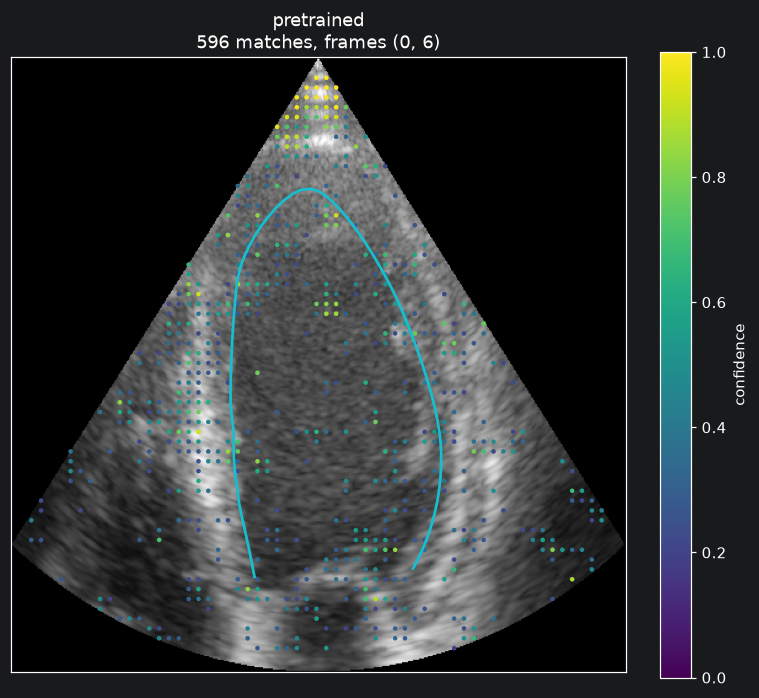

In [22]:
gap = min(6, len(frames) - 1 - reference_frame)
pair_cmp = (reference_frame, reference_frame + gap)

fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 6.5), squeeze=False)
for column, (label, model) in enumerate(models.items()):
    found = model.match(frames[pair_cmp[0]], frames[pair_cmp[1]])
    ax = axes[0, column]
    ax.imshow(frames[pair_cmp[0]])
    scatter = ax.scatter(found.xy0[:, 0], found.xy0[:, 1], c=found.confidence,
                         s=4, cmap="viridis", vmin=0, vmax=1)
    ax.plot(start_x - 1, start_y - 1, "-", color="tab:cyan", lw=1.8)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{label}\n{found.n_matches} matches, frames {pair_cmp}")
    fig.colorbar(scatter, ax=ax, fraction=0.046, label="confidence")
plt.tight_layout()
plt.show()

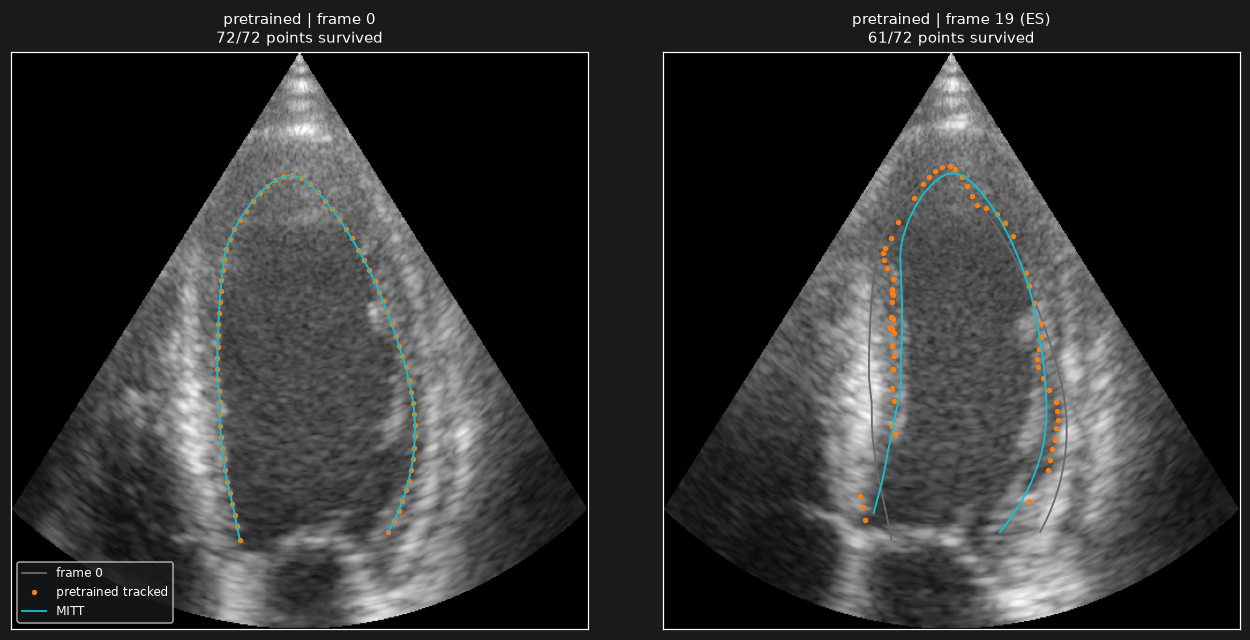

checkpoint      coverage   vs MITT   closure
pretrained         91.0%      5.60      2.67


In [23]:
# Tracked contour at ED and end-systole, per checkpoint.
tracked_cmp = {}
for label, model in models.items():
    tracked_cmp[label] = track_points(
        frames, start_x, start_y, model, pairing="reference",
        reference_frame=reference_frame, **INTERP,
    )

phases = [reference_frame, max(es_frame - 1, 0)]
fig, axes = plt.subplots(len(models), len(phases),
                         figsize=(6 * len(phases), 5.8 * len(models)), squeeze=False)
for row, (label, result) in enumerate(tracked_cmp.items()):
    finite = np.isfinite(result.x) & np.isfinite(result.y)
    for col, frame in enumerate(phases):
        ax = axes[row, col]
        ax.imshow(frames[frame])
        ax.plot(start_x - 1, start_y - 1, "-", color="dimgray", lw=1.2,
                label="frame 0")
        ax.plot(result.x[frame] - 1, result.y[frame] - 1, ".", color="tab:orange",
                ms=5, label=f"{label} tracked")
        if mitt is not None:
            ax.plot(mitt_x[frame] - 1, mitt_y[frame] - 1, "-", color="tab:cyan",
                    lw=1.2, label="MITT")
        ax.set_xticks([]); ax.set_yticks([])
        kept = int(finite[frame].sum())
        ax.set_title(f"{label} | frame {frame}"
                     f"{' (ES)' if frame == es_frame - 1 else ''}\n"
                     f"{kept}/{result.n_points} points survived", fontsize=10)
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

print(f"{'checkpoint':14s} {'coverage':>9s} {'vs MITT':>9s} {'closure':>9s}")
for label, result in tracked_cmp.items():
    finite = np.isfinite(result.x) & np.isfinite(result.y)
    closure = np.hypot(result.x[-1] - result.x[0], result.y[-1] - result.y[0])
    if mitt is not None:
        error = np.nanmedian(np.hypot(result.x - mitt_x, result.y - mitt_y))
    else:
        error = float("nan")
    print(f"{label:14s} {100 * finite.mean():8.1f}% {error:9.2f} "
          f"{np.nanmean(closure):9.2f}")

### Strain curves, per checkpoint

The end of the chain, and the only place the difference matters clinically.
A gap in a curve is a frame where some point went NaN, so the arc length is
undefined -- not a plotting artefact.

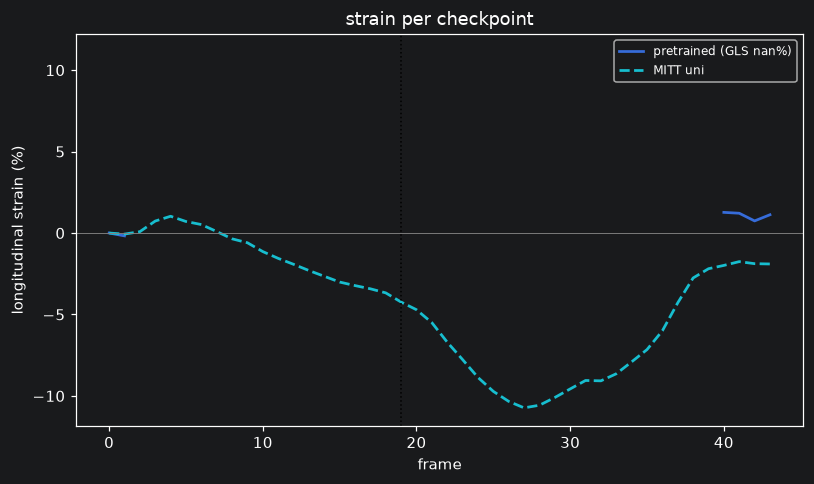

In [24]:
from motion_estimator.strain.curve import compute_strain

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, result in tracked_cmp.items():
    curve = compute_strain(*result.to_mm(spacing_xy), es_frame=es_frame,
                           drift_comp=drift_comp, open_contour=True)
    ax.plot(curve.curve.numpy(), lw=1.8, label=f"{label} (GLS {curve.value_es:.1f}%)")
if mitt is not None and mitt.strain_curve is not None:
    ax.plot(np.asarray(mitt.strain_curve).ravel(), color="tab:cyan", ls="--",
            lw=1.8, label=f"MITT {MITT_VARIANT}")
ax.axvline(es_frame - 1, color="k", ls=":", lw=1)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("frame"); ax.set_ylabel("longitudinal strain (%)")
ax.set_title("strain per checkpoint")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()